# Google Play Store Apps: Market Analysis

**Type:** Descriptive analytics & data cleaning
**Tools:** Python · pandas · NumPy · matplotlib · seaborn · SciPy
**Data:** ~10.8K Google Play Store app listings (scraped 2018) — [Kaggle: Google Play Store Apps](https://www.kaggle.com/datasets/lava18/google-play-store-apps)

---

## Client brief

A client planning to launch an Android app wants to understand the Google Play Store market before deciding **what to build and how to price it**. They supplied a raw export of app listings and asked for:

1. **A clean, analysis-ready dataset** — the raw export has missing values, duplicates, mixed units and text-encoded numbers.
2. **A visual overview of the market** — which categories are crowded, how free and paid apps are distributed, how apps are rated and installed.
3. **Answers to specific business questions** — does price relate to app size, which categories are most popular, how the market has grown, which paid apps succeed, whether top ratings can be trusted, and whether paid apps are rated differently from free ones.

## Contents

1. Setup & data loading
2. Data quality audit
3. Data cleaning
4. Market overview (visual analysis)
5. Business questions
6. Further analysis
7. Summary of findings & recommendations

## 1. Setup & data loading

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from scipy import stats
from pathlib import Path

# Display & plot settings
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid", palette="deep", font_scale=0.95)
plt.rcParams["figure.dpi"] = 110

# Charts used in the README are exported here
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

def save(name):
    """Save the current figure to figures/<name>.png."""
    plt.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", dpi=150)

In [2]:
raw = pd.read_csv("googleplaystore.csv")
print(f"Rows: {raw.shape[0]:,} | Columns: {raw.shape[1]}")
raw.head()

Rows: 10,841 | Columns: 13


,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
0,Photo Editor & Candy Camera & Grid & ScrapBook,ART_AND_DESIGN,4.10,159,19M,"10,000+",Free,0,Everyone,Art & Design,"January 7, 2018",1.0.0,4.0.3 and up
1,Coloring book moana,ART_AND_DESIGN,3.90,967,14M,"500,000+",Free,0,Everyone,Art & Design;Pretend Play,"January 15, 2018",2.0.0,4.0.3 and up
2,"U Launcher Lite – FREE Live Cool Themes, Hide ...",ART_AND_DESIGN,4.70,87510,8.7M,"5,000,000+",Free,0,Everyone,Art & Design,"August 1, 2018",1.2.4,4.0.3 and up
3,Sketch - Draw & Paint,ART_AND_DESIGN,4.50,215644,25M,"50,000,000+",Free,0,Teen,Art & Design,"June 8, 2018",Varies with device,4.2 and up
4,Pixel Draw - Number Art Coloring Book,ART_AND_DESIGN,4.30,967,2.8M,"100,000+",Free,0,Everyone,Art & Design;Creativity,"June 20, 2018",1.1,4.4 and up


**Columns at a glance**

| Column | Meaning |
|---|---|
| App, Category, Genres | App name and store classification |
| Rating | Average user rating (1–5) |
| Reviews | Number of user reviews |
| Size | Download size (e.g. `19M`, `201k`, `Varies with device`) |
| Installs | Install bucket (e.g. `10,000+`) |
| Type, Price | Free / Paid and price in USD (e.g. `$4.99`) |
| Content Rating | Target audience (Everyone, Teen, …) |
| Last Updated, Current Ver, Android Ver | Release information |

## 2. Data quality audit

Before changing anything, I check data types, missing values, duplicates and invalid values.

In [3]:
# Data types — most numeric fields are stored as text
raw.dtypes.to_frame("dtype").T

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
dtype,str,str,float64,str,str,str,str,str,str,str,str,str,str


In [4]:
# Missing values per column
missing = raw.isna().sum()
missing = (pd.DataFrame({"missing": missing, "% of rows": missing / len(raw) * 100})
             .query("missing > 0")
             .sort_values("missing", ascending=False))
missing

,missing,% of rows
Rating,1474,13.60
Current Ver,8,0.07
Android Ver,3,0.03
Content Rating,1,0.01
Type,1,0.01


In [5]:
# Duplicates: exact copies vs. the same app listed more than once
print(f"Exact duplicate rows      : {raw.duplicated().sum():,}")
print(f"Repeated app names        : {raw['App'].duplicated().sum():,}")
print(f"Unique apps               : {raw['App'].nunique():,}")

Exact duplicate rows      : 483
Repeated app names        : 1,181
Unique apps               : 9,660


In [6]:
# Rating must lie between 1 and 5 — one row breaks this rule
raw[(raw["Rating"] < 1) | (raw["Rating"] > 5)]

,App,Category,Rating,Reviews,Size,Installs,Type,Price,Content Rating,Genres,Last Updated,Current Ver,Android Ver
10472,Life Made WI-Fi Touchscreen Photo Frame,1.9,19.00,3.0M,"1,000+",Free,0,Everyone,NaN,"February 11, 2018",1.0.19,4.0 and up,NaN


**Audit findings**

- **Rating** is missing for ~13.6% of rows — the main quality issue.
- **One corrupted row** (*Life Made WI-Fi Touchscreen Photo Frame*): its values are shifted one column left, so Category holds `1.9`, Rating holds `19` and Genres is empty. The true category cannot be recovered.
- **Duplicates:** 483 exact copies, and 1,181 repeated app names in total — the same app was scraped at different times with different review counts.
- **Text-encoded numbers:** `Reviews`, `Size`, `Installs` and `Price` are strings with units and symbols (`M`, `k`, `+`, `,`, `$`).
- **Small gaps:** 1 missing `Type`, 8 missing `Current Ver`, 3 missing `Android Ver`.

## 3. Data cleaning

Each step below fixes one issue from the audit. The raw data stays untouched in `raw`; all cleaning happens on a copy, `df`.

### 3.1 Remove the corrupted row

In [7]:
df = raw.copy()

# The shifted row is the only one with a non-category value in 'Category'
corrupted = df["Category"] == "1.9"
df = df[~corrupted].copy()
print(f"Removed {corrupted.sum()} corrupted row → {len(df):,} rows")

Removed 1 corrupted row → 10,840 rows


### 3.2 Convert text columns to numbers

In [8]:
def size_to_mb(size):
    """'19M' → 19.0, '201k' → 0.196, 'Varies with device' → NaN."""
    if size.endswith("M"):
        return float(size[:-1])
    if size.endswith("k"):
        return float(size[:-1]) / 1024
    return np.nan

df["Reviews"]  = df["Reviews"].astype(int)
df["Size_MB"]  = df["Size"].apply(size_to_mb)
df["Installs"] = df["Installs"].str.replace(r"[+,]", "", regex=True).astype(int)
df["Price"]    = df["Price"].str.replace("$", "", regex=False).astype(float)
df["Last Updated"] = pd.to_datetime(df["Last Updated"], format="%B %d, %Y")
df["Year"]     = df["Last Updated"].dt.year

df = df.drop(columns="Size")
df[["Reviews", "Size_MB", "Installs", "Price", "Last Updated", "Year"]].describe().T

,count,mean,min,25%,50%,75%,max,std
Reviews,"10,840.00","444,152.90",0.00,38.00,"2,094.00","54,775.50","78,158,306.00","2,927,760.60"
Size_MB,"9,145.00",21.52,0.01,4.90,13.00,30.00,100.00,22.59
Installs,"10,840.00","15,464,338.88",0.00,"1,000.00","100,000.00","5,000,000.00","1,000,000,000.00","85,029,361.40"
Price,"10,840.00",1.03,0.00,0.00,0.00,0.00,400.00,15.95
Last Updated,10840,2017-11-21 06:43:02.435424,2010-05-21 00:00:00,2017-09-20 00:00:00,2018-05-24 00:00:00,2018-07-20 00:00:00,2018-08-08 00:00:00,NaN
Year,"10,840.00","2,017.40","2,010.00","2,017.00","2,018.00","2,018.00","2,018.00",1.10


*`Installs` is a lower bound (a bucket such as "10,000+"), so it is used as an ordinal measure of popularity rather than an exact count. `Size` "Varies with device" (~15% of apps) becomes NaN, because no single size exists.*

### 3.3 Remove duplicate apps

When an app appears several times, I keep the listing with the **most reviews** — the most recent snapshot of that app.

In [9]:
before = len(df)
df = (df.sort_values("Reviews", ascending=False)
        .drop_duplicates(subset="App", keep="first")
        .reset_index(drop=True))
print(f"Rows: {before:,} → {len(df):,}  ({before - len(df):,} duplicate listings removed)")

Rows: 10,840 → 9,659  (1,181 duplicate listings removed)


### 3.4 Handle missing values

In [10]:
# Why is Rating missing? Compare review counts of rated vs. unrated apps
df.assign(rating_missing=df["Rating"].isna()) \
  .groupby("rating_missing")["Reviews"] \
  .describe()[["count", "50%", "mean", "max"]] \
  .rename(columns={"50%": "median reviews", "mean": "mean reviews"})

,count,median reviews,mean reviews,max
rating_missing,,,,
False,"8,196.00","3,017.00","255,500.78","78,158,306.00"
True,"1,463.00",1.00,18.13,"3,248.00"


Apps with no rating have a **median of 1 review** versus ~3,000 for rated apps — the rating is missing because almost nobody has rated these apps yet, not because of a data error.

**Decision:** I keep `Rating` as missing instead of filling it with an average. Imputing ~1,460 identical values would make ratings look more uniform than they are and would distort the confidence interval and t-test in Section 5. Rating-based analysis uses the ~8,200 rated apps; a `Rated` flag records which apps have a rating.

In [11]:
df["Rated"] = df["Rating"].notna()

# Type: the one missing value belongs to a $0 app → Free
df["Type"] = df["Type"].fillna("Free")

# Version fields: missing means the version is not published
df[["Current Ver", "Android Ver"]] = df[["Current Ver", "Android Ver"]].fillna("Unknown")

# Remaining missing values — Rating and Size_MB stay NaN by design
df.isna().sum()[lambda s: s > 0]

Rating     1463
Size_MB    1228
dtype: int64

### 3.5 Clean dataset

In [12]:
print(f"Clean dataset: {len(df):,} apps × {df.shape[1]} columns "
      f"| {df['Rated'].sum():,} rated apps")
df.info()

Clean dataset: 9,659 apps × 15 columns | 8,196 rated apps
<class 'pandas.DataFrame'>
RangeIndex: 9659 entries, 0 to 9658
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   App             9659 non-null   str           
 1   Category        9659 non-null   str           
 2   Rating          8196 non-null   float64       
 3   Reviews         9659 non-null   int64         
 4   Installs        9659 non-null   int64         
 5   Type            9659 non-null   str           
 6   Price           9659 non-null   float64       
 7   Content Rating  9659 non-null   str           
 8   Genres          9659 non-null   str           
 9   Last Updated    9659 non-null   datetime64[us]
 10  Current Ver     9659 non-null   str           
 11  Android Ver     9659 non-null   str           
 12  Size_MB         8431 non-null   float64       
 13  Year            9659 non-null   int32         
 14  Rated    

## 4. Market overview

### 4.1 Number of apps per category

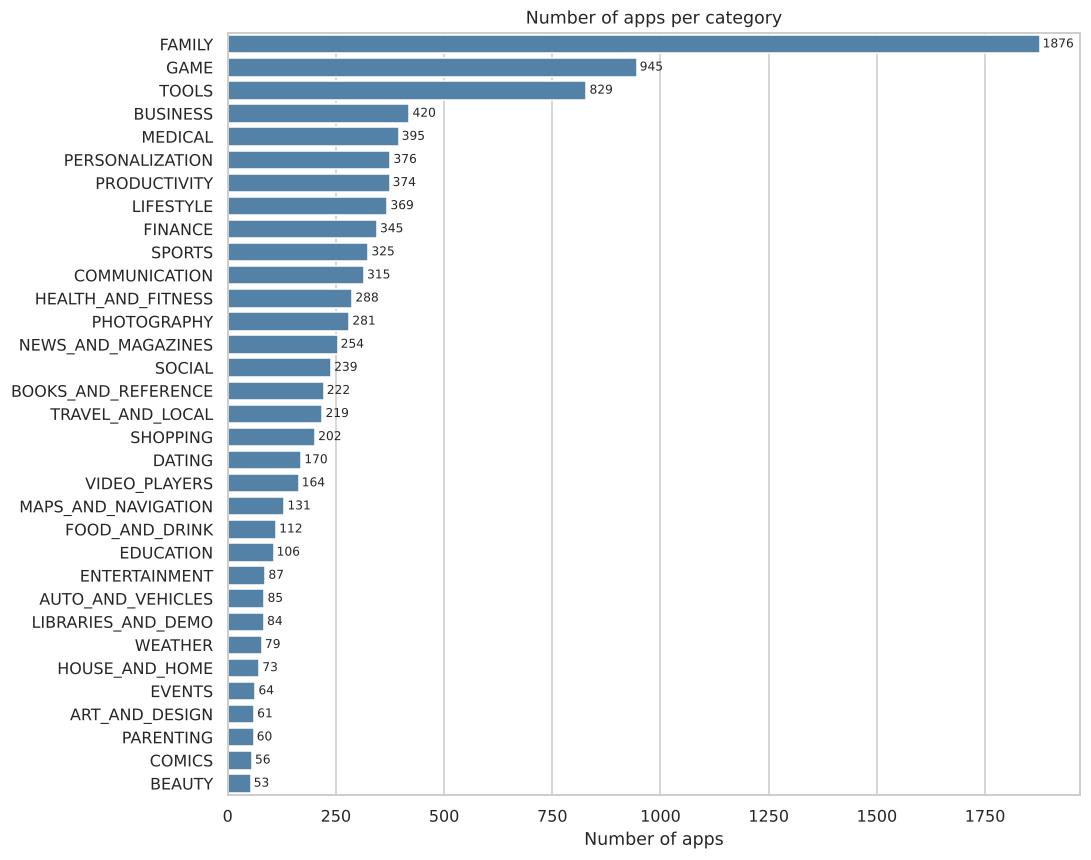

In [13]:
cat_counts = df["Category"].value_counts()

plt.figure(figsize=(10, 9))
ax = sns.barplot(x=cat_counts.values, y=cat_counts.index, color="steelblue")
ax.bar_label(ax.containers[0], fontsize=8, padding=2)
plt.title("Number of apps per category")
plt.xlabel("Number of apps")
plt.ylabel("")
save("apps_per_category")
plt.show()

**Family** (~1,880 apps) and **Game** (~945) dominate, followed by **Tools** (~830). Together the top 3 categories hold ~38% of all apps — these are the most crowded markets for a new app.

### 4.2 Free vs. paid apps across categories

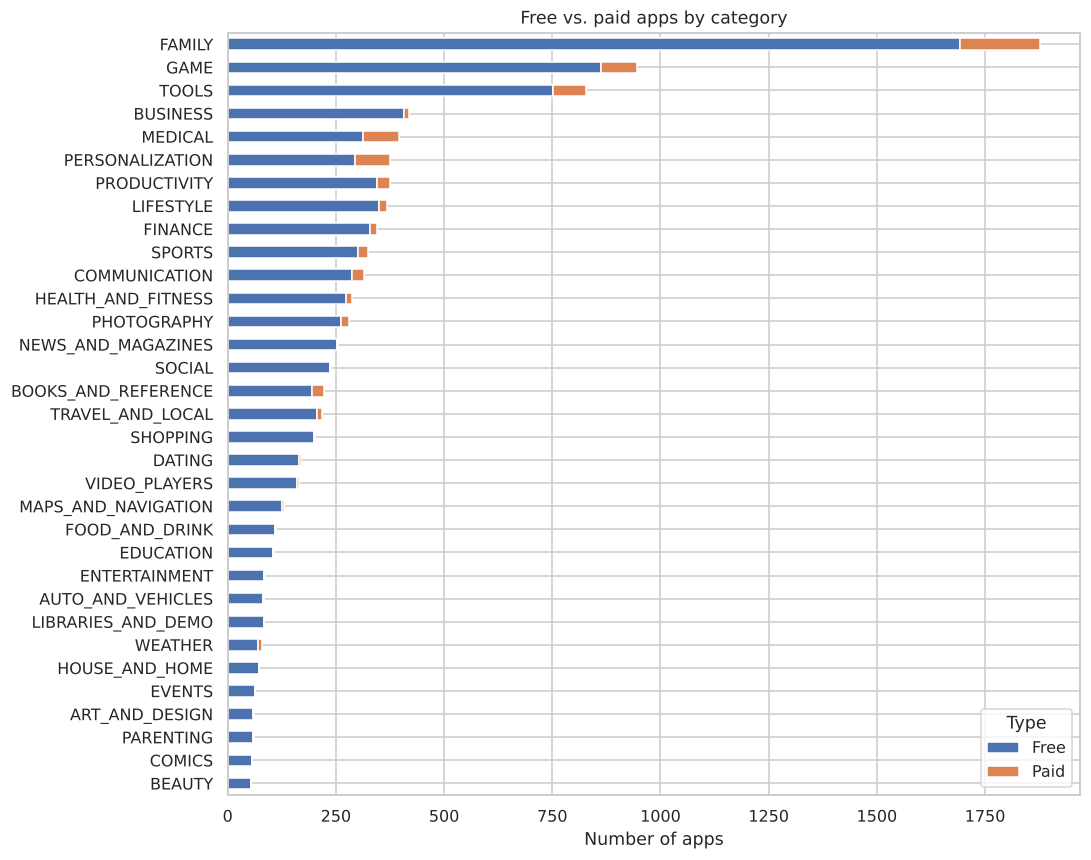

Paid apps overall: 7.8%


In [14]:
type_by_cat = (pd.crosstab(df["Category"], df["Type"])
                 .assign(Total=lambda t: t.sum(axis=1))
                 .sort_values("Total"))

ax = type_by_cat[["Free", "Paid"]].plot(kind="barh", stacked=True, figsize=(10, 9),
                                        color=["#4C72B0", "#DD8452"])
plt.title("Free vs. paid apps by category")
plt.xlabel("Number of apps")
plt.ylabel("")
save("free_vs_paid")
plt.show()

print(f"Paid apps overall: {(df['Type'] == 'Paid').mean():.1%}")

In [15]:
# Categories where paid apps are most common (share of paid apps)
paid_share = (type_by_cat["Paid"] / type_by_cat["Total"]).sort_values(ascending=False)
paid_share.head(8).to_frame("% paid").style.format("{:.1%}")

,% paid
Category,
PERSONALIZATION,21.5%
MEDICAL,20.8%
BOOKS_AND_REFERENCE,12.6%
WEATHER,10.1%
FAMILY,9.9%
TOOLS,9.4%
GAME,8.7%
COMMUNICATION,8.6%


Only **~8%** of apps are paid. Paid apps are most common in niche, utility-driven categories — **Personalization (22%), Medical (21%), Books & Reference (13%) and Weather (10%)** — where users pay for a specific function. In mass-market categories such as Social, Entertainment and Shopping, only 2–3 apps each are paid.

### 4.3 Distribution of ratings (1–5)

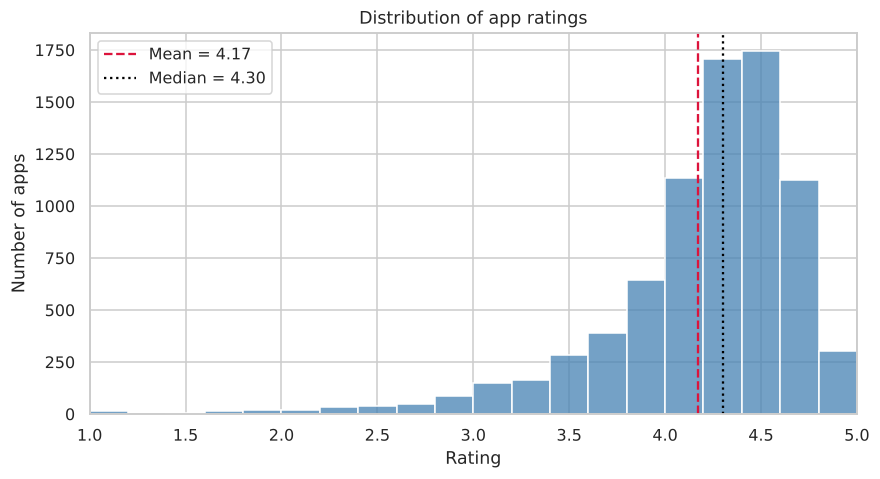

,count,mean,std,min,25%,50%,75%,max
Rating,"8,196.00",4.17,0.54,1.00,4.00,4.30,4.50,5.00


In [16]:
rated = df[df["Rated"]]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(rated["Rating"], bins=np.arange(1, 5.2, 0.2), color="steelblue", ax=ax)
ax.axvline(rated["Rating"].mean(), color="crimson", ls="--",
           label=f"Mean = {rated['Rating'].mean():.2f}")
ax.axvline(rated["Rating"].median(), color="black", ls=":",
           label=f"Median = {rated['Rating'].median():.2f}")
ax.set(title="Distribution of app ratings", xlabel="Rating", ylabel="Number of apps", xlim=(1, 5))
ax.legend()
save("rating_distribution")
plt.show()

rated["Rating"].describe().to_frame().T

Ratings are strongly **left-skewed**: half of all apps score 4.3 or higher and only ~6% score below 3.3. On the Play Store a rating of 4.0 is average, not good — a new app needs **4.5+** to stand out.

### 4.4 Rating outliers by category

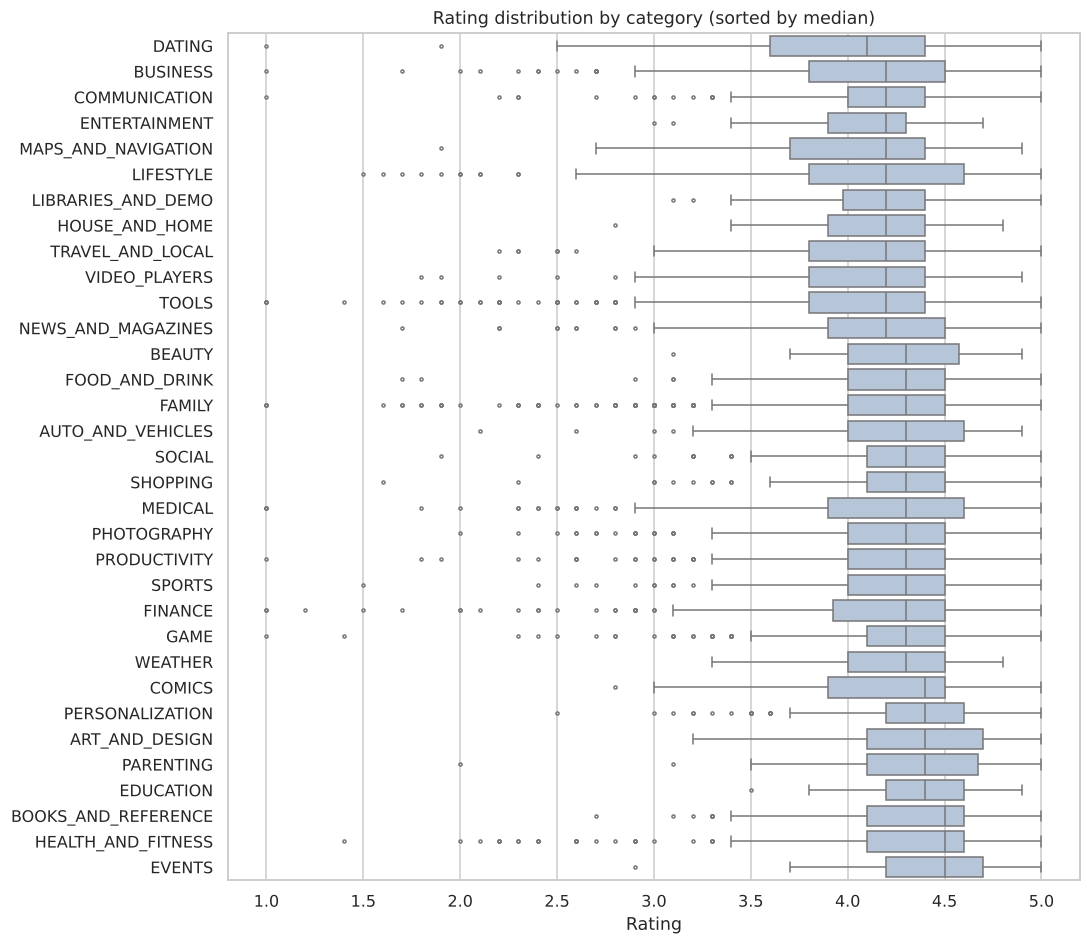

In [17]:
order = rated.groupby("Category")["Rating"].median().sort_values().index

plt.figure(figsize=(10, 10))
sns.boxplot(data=rated, y="Category", x="Rating", order=order, color="lightsteelblue",
            fliersize=2)
plt.title("Rating distribution by category (sorted by median)")
plt.xlabel("Rating")
plt.ylabel("")
save("rating_by_category")
plt.show()

In [18]:
# Outliers using the IQR rule
q1, q3 = rated["Rating"].quantile([0.25, 0.75])
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr

df["Rating_outlier"] = df["Rated"] & ~df["Rating"].between(low, high)
print(f"IQR bounds: {low:.2f} – {high:.2f}")
print(f"Outliers  : {df['Rating_outlier'].sum():,} apps "
      f"({df['Rating_outlier'].sum() / df['Rated'].sum():.1%} of rated apps), all on the low side")

IQR bounds: 3.25 – 5.25
Outliers  : 491 apps (6.0% of rated apps), all on the low side


**Handling decision:** all outliers are **low ratings** (below ~3.3), and every value is valid on the 1–5 scale. They are genuinely poor apps, not errors, so removing them would make the market look better than it is. I **keep them and flag them** in `Rating_outlier`, so any later model can include or exclude them.

The boxplot also shows that **Events, Health & Fitness and Books & Reference** have the highest median ratings (4.5), while **Dating** has the lowest (4.1). **Lifestyle and Medical** show the widest spread — app quality there is very uneven.

### 4.5 Installs by category

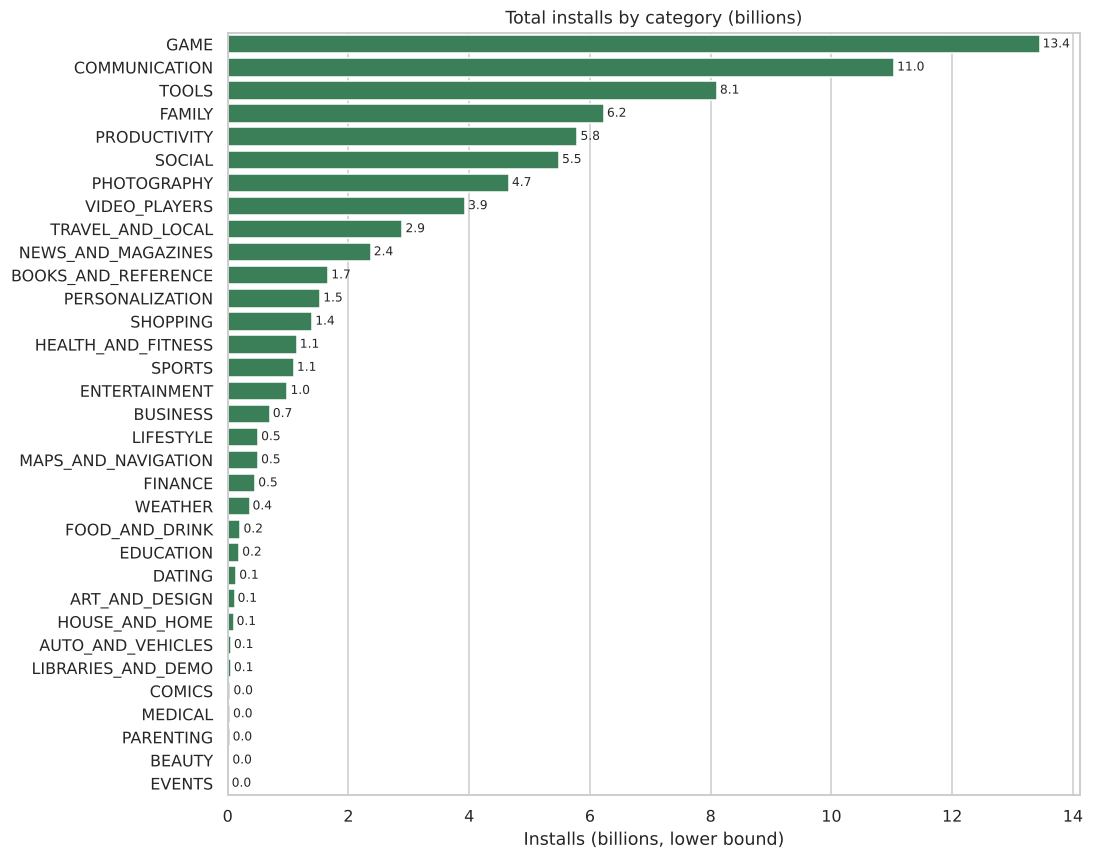

In [19]:
installs_by_cat = (df.groupby("Category")["Installs"].sum()
                     .sort_values(ascending=False) / 1e9)

plt.figure(figsize=(10, 9))
ax = sns.barplot(x=installs_by_cat.values, y=installs_by_cat.index, color="seagreen")
ax.bar_label(ax.containers[0], fmt="%.1f", fontsize=8, padding=2)
plt.title("Total installs by category (billions)")
plt.xlabel("Installs (billions, lower bound)")
plt.ylabel("")
save("installs_by_category")
plt.show()

Installs are very concentrated: **Game (~13.5B), Communication (~11B) and Tools (~8B)** lead. **Family** ranks only 4th despite having twice as many apps as Game — lots of supply, less demand per app.

---

## 5. Business questions

### Q1. Does price correlate with app size?

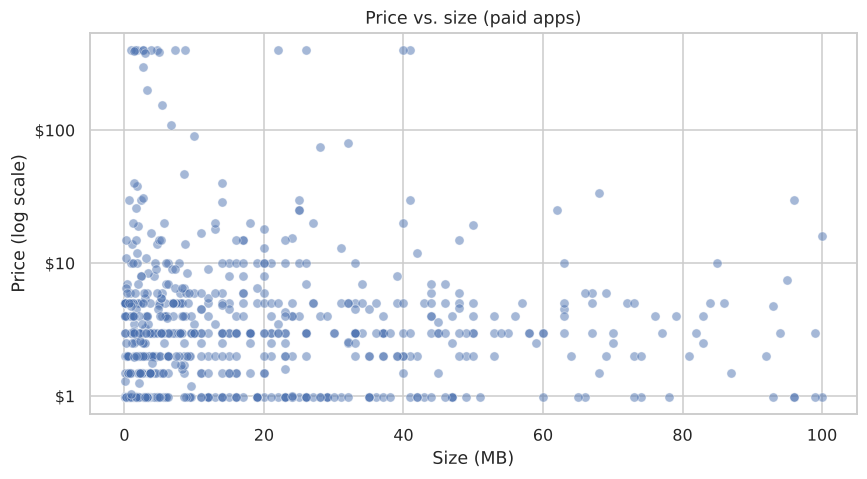

Pearson r  = -0.065
Spearman ρ = 0.045 (p = 0.240)


In [20]:
paid = df[(df["Type"] == "Paid") & df["Size_MB"].notna()]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(data=paid, x="Size_MB", y="Price", alpha=0.5, ax=ax)
ax.set_yscale("log")
ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
ax.set(title="Price vs. size (paid apps)", xlabel="Size (MB)", ylabel="Price (log scale)")
save("price_vs_size")
plt.show()

pearson = paid[["Size_MB", "Price"]].corr().iloc[0, 1]
spearman, p = stats.spearmanr(paid["Size_MB"], paid["Price"])
print(f"Pearson r  = {pearson:.3f}")
print(f"Spearman ρ = {spearman:.3f} (p = {p:.3f})")

**Answer: No meaningful relationship.** I use paid apps only — free apps all sit at $0 and would hide any pattern. Both Pearson (linear) and Spearman (rank) correlations are close to zero. Price is set by the value of the function, not by how large the app is. The most expensive apps ($200–$400) are small novelty apps ("I am rich"-style), not large games.

### Q2. Which categories are the most popular?

Popularity has two sides: **demand** (installs) and **satisfaction** (rating). I rank each category on both and combine the ranks.

In [21]:
cat_summary = (df.groupby("Category")
                 .agg(apps=("App", "count"),
                      median_installs=("Installs", "median"),
                      total_installs_bn=("Installs", lambda s: s.sum() / 1e9),
                      avg_rating=("Rating", "mean"))
                 .assign(install_rank=lambda t: t["median_installs"].rank(ascending=False),
                         rating_rank=lambda t: t["avg_rating"].rank(ascending=False))
                 .assign(popularity_score=lambda t: t[["install_rank", "rating_rank"]].mean(axis=1))
                 .sort_values("popularity_score"))

cat_summary.head(10).style.format({"median_installs": "{:,.0f}", "total_installs_bn": "{:.2f}",
                                   "avg_rating": "{:.2f}", "install_rank": "{:.0f}",
                                   "rating_rank": "{:.0f}", "popularity_score": "{:.1f}"})

,apps,median_installs,total_installs_bn,avg_rating,install_rank,rating_rank,popularity_score
Category,,,,,,,
EDUCATION,106,"1,000,000",0.19,4.35,4,3,3.5
GAME,945,"1,000,000",13.45,4.24,4,9,6.5
WEATHER,79,"1,000,000",0.36,4.24,4,10,7.0
SHOPPING,202,"1,000,000",1.40,4.23,4,12,8.0
ART_AND_DESIGN,61,"100,000",0.11,4.36,15,2,8.5
PARENTING,60,"100,000",0.03,4.30,15,6,10.5
SOCIAL,239,"100,000",5.49,4.25,15,8,11.5
PHOTOGRAPHY,281,"1,000,000",4.66,4.16,4,21,12.5
HEALTH_AND_FITNESS,288,"100,000",1.14,4.24,15,11,13.0


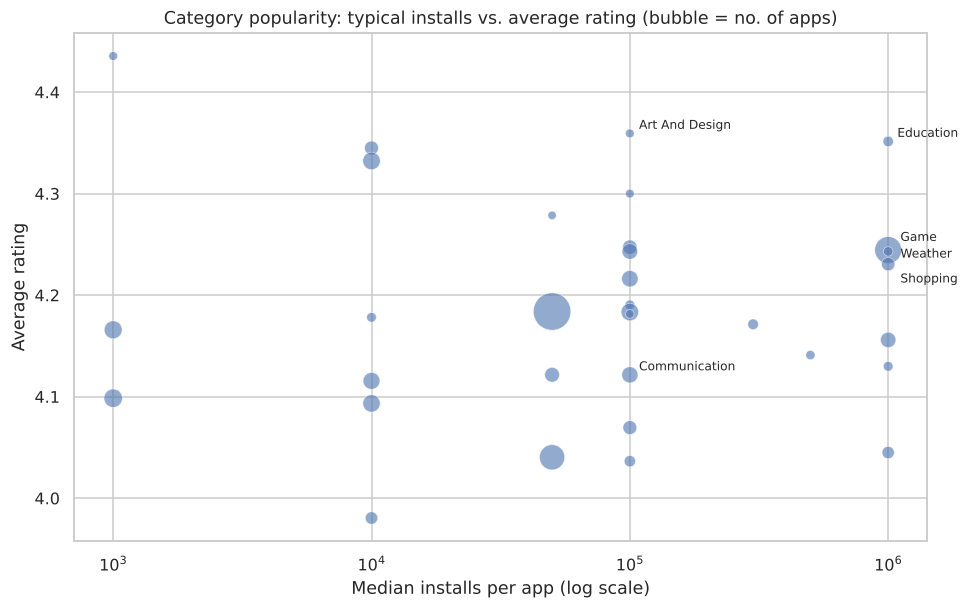

In [22]:
fig, ax = plt.subplots(figsize=(10, 6))
sns.scatterplot(data=cat_summary, x="median_installs", y="avg_rating", size="apps",
                sizes=(30, 600), alpha=0.6, legend=False, ax=ax)
# Label the top 5 categories plus the largest one by total installs
offsets = {"GAME": (8, 6), "WEATHER": (8, -4), "SHOPPING": (8, -12)}
for cat in list(cat_summary.head(5).index) + ["COMMUNICATION"]:
    row = cat_summary.loc[cat]
    ax.annotate(cat.replace("_", " ").title(), (row["median_installs"], row["avg_rating"]),
                fontsize=8, xytext=offsets.get(cat, (6, 3)), textcoords="offset points")
ax.set_xscale("log")
ax.set(title="Category popularity: typical installs vs. average rating (bubble = no. of apps)",
       xlabel="Median installs per app (log scale)", ylabel="Average rating")
save("category_popularity")
plt.show()

**Answer:** Using median installs (a typical app, not one blockbuster) and average rating together, the strongest categories are **Education, Game, Weather, Shopping and Art & Design** — a typical app there reaches 100K–1M installs *and* averages 4.2–4.4 stars. **Communication** has the second-largest total installs, but a typical communication app only reaches 100K installs and averages 4.12 — its total is driven by a handful of giants (WhatsApp, Messenger, Hangouts).

### Q3. How many apps are produced each year, by category?

`Last Updated` is the closest available proxy for release activity. The year comes from the date conversion in Section 3.2.

In [23]:
apps_per_year = df["Year"].value_counts().sort_index()
print(f"Year with the most apps: {apps_per_year.idxmax()} ({apps_per_year.max():,} apps)")
apps_per_year.to_frame("apps").T

Year with the most apps: 2018 (6,287 apps)


Year,2010,2011,2012,2013,2014,2015,2016,2017,2018
apps,1,15,26,108,203,448,779,1792,6287


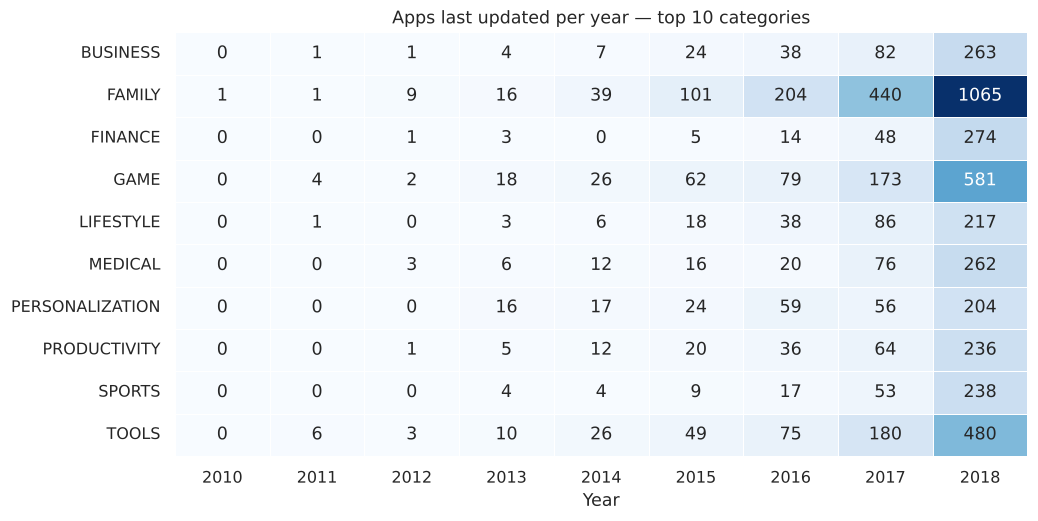

In [24]:
top_cats = df["Category"].value_counts().head(10).index
year_cat = pd.crosstab(df.loc[df["Category"].isin(top_cats), "Category"],
                       df.loc[df["Category"].isin(top_cats), "Year"])

plt.figure(figsize=(10, 5))
sns.heatmap(year_cat, annot=True, fmt="d", cmap="Blues", cbar=False, linewidths=0.5)
plt.title("Apps last updated per year — top 10 categories")
plt.xlabel("Year")
plt.ylabel("")
save("apps_per_year_category")
plt.show()

In [25]:
# Categories with the most apps in the peak year
peak = apps_per_year.idxmax()
df.loc[df["Year"] == peak, "Category"].value_counts().head(5).to_frame(f"apps in {peak}")

,apps in 2018
Category,
FAMILY,1065
GAME,581
TOOLS,480
FINANCE,274
BUSINESS,263


**Answer:** **2018** has by far the most apps (~6,300, about two-thirds of the store), and activity grows every year from 2010. Since the data was scraped in 2018, this partly reflects active maintenance: most live apps had been updated recently. **Family, Game and Tools** lead in 2018, matching their overall share.

### Q4. Which paid apps have the highest price and a good rating?

"Good rating" = 4.5 or above, with at least **100 reviews** so the rating is reliable (see Q5).

In [26]:
good_paid = (df[(df["Type"] == "Paid") & (df["Rating"] >= 4.5) & (df["Reviews"] >= 100)]
               .sort_values("Price", ascending=False)
               [["App", "Category", "Price", "Rating", "Reviews", "Installs"]])

print(f"Paid apps rated 4.5+ with 100+ reviews: {len(good_paid)}")
good_paid.head(10)

Paid apps rated 4.5+ with 100+ reviews: 173


,App,Category,Price,Rating,Reviews,Installs
4120,Human Anatomy Atlas 2018: Complete 3D Human Body,MEDICAL,24.99,4.50,2923,100000
3437,DRAGON QUEST VIII,FAMILY,19.99,4.50,7812,50000
5333,I am Rich Premium Plus,FINANCE,18.99,4.60,459,10000
3877,The World Ends With You,GAME,17.99,4.60,4108,10000
4517,DRAGON QUEST IV,FAMILY,14.99,4.70,1647,10000
4504,DRAGON QUEST V,FAMILY,14.99,4.70,1667,10000
3638,Carrier Landings Pro,FAMILY,12.99,4.60,5969,10000
3601,BackCountry Navigator TOPO GPS PRO,MAPS_AND_NAVIGATION,11.99,4.50,6230,100000
5862,EMT Review Plus,MEDICAL,11.99,4.50,199,10000
5971,go41cx,FAMILY,10.00,4.80,171,1000


**Answer:** The highest-priced well-rated apps are **premium games** (the Dragon Quest series, $15–$20) and **specialist professional tools** — a 3D human anatomy atlas ($24.99), an EMT exam app, a GPS navigator and a flight simulator — priced roughly $10–$25. Without the review filter, the top of the list would be dominated by $400 "I am rich" novelty apps; even with it, one such app still appears, a reminder that price alone does not signal value.

### Q5. Are top-rated apps genuine? Checking their review counts

In [27]:
top_rated = df[df["Rating"] == 5.0]

print(f"Apps with a perfect 5.0 rating: {len(top_rated)}")
print(f"Median reviews of 5.0 apps    : {top_rated['Reviews'].median():.0f}")
print(f"5.0 apps with < 100 reviews   : {(top_rated['Reviews'] < 100).mean():.0%}")

bins = [0, 10, 50, 100, 1_000, np.inf]
labels = ["1–10", "11–50", "51–100", "101–1,000", "1,000+"]
pd.cut(top_rated["Reviews"], bins=bins, labels=labels).value_counts().sort_index() \
  .to_frame("5.0-rated apps")

Apps with a perfect 5.0 rating: 271
Median reviews of 5.0 apps    : 4
5.0 apps with < 100 reviews   : 99%


,5.0-rated apps
Reviews,
1–10,221
11–50,45
51–100,2
"101–1,000",3
"1,000+",0


**Answer: Mostly not reliable.** 99% of the 271 apps rated 5.0 have fewer than 100 reviews; the median is just **4 reviews**, and 221 of them have 10 or fewer. Not a single 5.0 app has more than ~1,000 reviews. A perfect score is a sign of a **small sample**, not exceptional quality.

### Q6. Why can apps with very few reviews have top ratings?

The chart below plots rating against the number of reviews for every rated app.

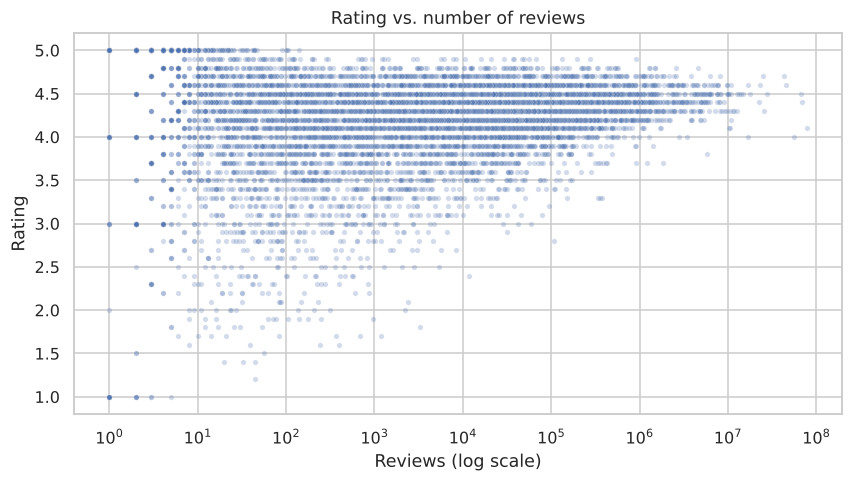

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(data=rated, x="Reviews", y="Rating", alpha=0.25, s=12, ax=ax)
ax.set_xscale("log")
ax.set(title="Rating vs. number of reviews", xlabel="Reviews (log scale)", ylabel="Rating")
save("rating_vs_reviews")
plt.show()

**Answer:** The chart forms a **funnel**: with few reviews, ratings spread across the full 1–5 range; as reviews grow, ratings converge to roughly 4.0–4.6. Reasons a low-review app can hold a top rating:

1. **Small-sample effect** — with 3 reviews, three 5-star ratings give a perfect average; one unhappy user would drop it sharply.
2. **Friends, family and the developer** — the first reviews often come from people close to the developer.
3. **New or niche apps** — early adopters actively sought the app out and are naturally positive.
4. **Incentivised or fake reviews** — easiest to influence when the total is small.

For decisions, ratings should be read together with review counts — for example, by requiring at least 100 reviews, as in Q4.

### Q7. What is the 95% confidence interval for the average app rating?

In [29]:
ratings = rated["Rating"]
n, mean, sem = len(ratings), ratings.mean(), stats.sem(ratings)
ci_low, ci_high = stats.t.interval(0.95, df=n - 1, loc=mean, scale=sem)

print(f"n = {n:,} rated apps")
print(f"Mean rating = {mean:.3f}, standard error = {sem:.4f}")
print(f"95% CI for the mean rating: [{ci_low:.3f}, {ci_high:.3f}]")

n = 8,196 rated apps
Mean rating = 4.173, standard error = 0.0059
95% CI for the mean rating: [4.162, 4.185]


**Answer:** The 95% confidence interval for the mean rating is roughly **[4.16, 4.19]**. We can be 95% confident that the true average rating of Play Store apps lies in this narrow range — narrow because the sample is large (~8,200 apps). This is an interval for the **average**; individual apps still vary widely (standard deviation ≈ 0.54).

### Q8. Are paid apps rated differently from free apps? (t-test)

- **H₀:** mean rating of free apps = mean rating of paid apps
- **H₁:** the means are different (two-sided)
- **Test:** Welch's independent-samples t-test (does not assume equal variances — the groups differ greatly in size), α = 0.05

In [30]:
free_r = rated.loc[rated["Type"] == "Free", "Rating"]
paid_r = rated.loc[rated["Type"] == "Paid", "Rating"]

t_stat, p_val = stats.ttest_ind(free_r, paid_r, equal_var=False)

# Effect size (Cohen's d) — how large the difference is in practice
pooled_sd = np.sqrt(((len(free_r) - 1) * free_r.var() + (len(paid_r) - 1) * paid_r.var())
                    / (len(free_r) + len(paid_r) - 2))
cohens_d = (paid_r.mean() - free_r.mean()) / pooled_sd

pd.DataFrame({"n": [len(free_r), len(paid_r)],
              "mean rating": [free_r.mean(), paid_r.mean()],
              "std": [free_r.std(), paid_r.std()]},
             index=["Free", "Paid"])

,n,mean rating,std
Free,7594,4.17,0.53
Paid,602,4.26,0.56


In [31]:
print(f"t = {t_stat:.3f}, p-value = {p_val:.4f}")
print(f"Cohen's d = {cohens_d:.3f}")
print("Decision:", "Reject H₀" if p_val < 0.05 else "Fail to reject H₀", "at α = 0.05")

t = -4.080, p-value = 0.0001
Cohen's d = 0.179
Decision: Reject H₀ at α = 0.05


In [32]:
# Robustness check: ratings are skewed, so also run the non-parametric Mann–Whitney U test
u_stat, p_mw = stats.mannwhitneyu(free_r, paid_r, alternative="two-sided")
print(f"Mann–Whitney U p-value = {p_mw:.4f}")

Mann–Whitney U p-value = 0.0000


**Answer:** Paid apps are rated slightly higher on average (4.26 vs. 4.17). The difference is **statistically significant** (Welch t = −4.08, p ≈ 0.0001; Mann–Whitney p < 0.001), so I reject H₀. The **effect size is small**, though (Cohen's d ≈ 0.18): charging for an app is linked with only a marginally better rating. Users who pay are a self-selected, committed group, and that explains part of the gap.

---

## 6. Further analysis

Beyond the brief, three questions matter to a client choosing what to build.

### 6.1 Does popularity mean quality? Rating by install tier

In [33]:
tiers = pd.cut(df["Installs"],
               bins=[-1, 1_000, 100_000, 10_000_000, np.inf],
               labels=["≤1K", "1K–100K", "100K–10M", "10M+"])

tier_summary = (df.assign(Install_tier=tiers)
                  .groupby("Install_tier", observed=True)
                  .agg(apps=("App", "count"),
                       rated_share=("Rated", "mean"),
                       avg_rating=("Rating", "mean"),
                       median_reviews=("Reviews", "median")))
tier_summary.style.format({"rated_share": "{:.0%}", "avg_rating": "{:.2f}",
                           "median_reviews": "{:,.0f}"})

,apps,rated_share,avg_rating,median_reviews
Install_tier,,,,
≤1K,2677,50%,4.20,4
1K–100K,3080,96%,4.06,382
100K–10M,3465,100%,4.23,"38,961"
10M+,437,100%,4.35,"1,536,349"


Apps under 1K installs show a deceptively high average (4.20), but only half of them are rated at all, with a median of 4 reviews — the small-sample effect from Q5. Among reliably rated apps, ratings **rise with popularity**: from 4.06 (1K–100K installs) to 4.23 (100K–10M) and 4.35 (10M+). Popular apps are not only bigger — they are also better rated.

### 6.2 Reviews as a proxy for installs

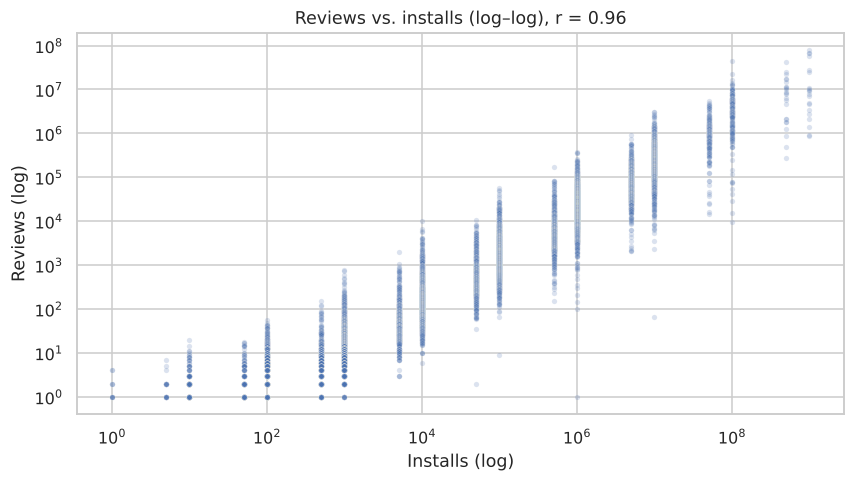

In [34]:
r = np.corrcoef(np.log10(df["Reviews"] + 1), np.log10(df["Installs"] + 1))[0, 1]

fig, ax = plt.subplots(figsize=(9, 4.5))
sns.scatterplot(data=df, x="Installs", y="Reviews", alpha=0.2, s=12, ax=ax)
ax.set(xscale="log", yscale="log", title=f"Reviews vs. installs (log–log), r = {r:.2f}",
       xlabel="Installs (log)", ylabel="Reviews (log)")
save("reviews_vs_installs")
plt.show()

On a log scale, reviews and installs are **very strongly correlated** (r ≈ 0.96): the typical app gets about 1 review per 60 installs. A new app can use its review count as a near real-time estimate of its install growth.

### 6.3 Does keeping an app updated matter?

In [35]:
ref_date = df["Last Updated"].max()
df["Months_since_update"] = (ref_date - df["Last Updated"]).dt.days / 30.44

freshness = pd.cut(df["Months_since_update"], bins=[-1, 3, 12, 24, np.inf],
                   labels=["< 3 months", "3–12 months", "1–2 years", "2+ years"])

(df.assign(Last_update=freshness)
   .groupby("Last_update", observed=True)
   .agg(apps=("App", "count"), avg_rating=("Rating", "mean"),
        median_installs=("Installs", "median"))
   .style.format({"avg_rating": "{:.2f}", "median_installs": "{:,.0f}"}))

,apps,avg_rating,median_installs
Last_update,,,
< 3 months,4785,4.25,"500,000"
3–12 months,2458,4.13,"10,000"
1–2 years,1205,4.06,"10,000"
2+ years,1211,4.05,"10,000"


Apps updated in the last 3 months have the **highest average rating (4.25) and 50× higher median installs** (500K vs. 10K) than apps not updated for longer. Ratings keep falling the longer an app goes without an update, down to 4.05 after 2+ years. Regular updates go hand in hand with user satisfaction and growth (a correlation, not proof of cause: successful apps also have more resources to keep updating).

---

## 7. Summary of findings & recommendations

**Data quality**
- 10,841 raw rows → **9,659 unique apps** after removing 1 corrupted row and 1,181 duplicate listings.
- Missing ratings (~15%) belong to apps with almost no reviews, so they are flagged, not imputed. Sizes, installs, prices and dates are converted to numeric types.

**Market insights**
1. **Crowded vs. rewarding categories:** Family, Game and Tools have the most apps. Education, Game, Weather and Shopping combine high typical installs with strong ratings.
2. **Free dominates:** ~92% of apps are free. Paid apps are most common in niche categories (Personalization, Medical, Books & Reference, Weather); well-rated paid apps sit around $10–$25.
3. **Price is unrelated to size** — users pay for function, not megabytes.
4. **The rating bar is high:** median rating 4.3, 95% CI for the mean ≈ [4.16, 4.19]. An app needs 4.5+ to stand out.
5. **Perfect ratings are a small-sample effect:** 99% of 5.0 apps have fewer than 100 reviews (median: 4).
6. **Paid apps are rated slightly higher** than free apps (4.26 vs. 4.17) — statistically significant but a small effect.
7. **Popular, recently updated apps rate best** — installs, reviews, ratings and update frequency move together.

**Recommendations for the client**
- Launch as **free** (with in-app purchases or a premium tier) unless targeting a specialist niche where users pay for a clear function.
- Prioritise categories with **strong demand per app and high satisfaction** (Education, Weather, Shopping) over the most crowded ones (Family, Tools).
- Plan for a **4.5+ rating** and a steady **update cadence** (at least every 3 months).
- Judge competitor ratings together with review counts — ignore perfect scores under ~100 reviews.